In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Must match the seed used in 04_run_experiments.ipynb
seed = 0

project_root = Path.cwd().parent
fold_path = project_root / "results" / "raw_scores" / f"seed_{seed}_perfold.csv"
fig_dir = project_root / "results" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

d = pd.read_csv(fold_path)

classification = ["Breast Cancer", "Car Evaluation", "House Votes"]
regression = ["Abalone", "Computer Hardware", "Forest Fires"]
order = classification + regression

d["dataset"] = pd.Categorical(d["dataset"], categories=order, ordered=True)
print(f"{len(d)} rows ({d['dataset'].nunique()} datasets x {d.groupby('dataset', observed=True).size().iloc[0]} folds)")

60 rows (6 datasets x 10 folds)


In [2]:
g = d.groupby("dataset", observed=True)

summary = pd.DataFrame({
    "Unpruned error": g["unpruned_err"].mean(),
    "Unpruned error SD": g["unpruned_err"].std(),
    "Pruned error": g["pruned_err"].mean(),
    "Pruned error SD": g["pruned_err"].std(),
    "Unpruned nodes": g["unpruned_size"].mean(),
    "Unpruned nodes SD": g["unpruned_size"].std(),
    "Pruned nodes": g["pruned_size"].mean(),
    "Pruned nodes SD": g["pruned_size"].std(),
})

summary["Error change (%)"] = 100 * (summary["Pruned error"] - summary["Unpruned error"]) / summary["Unpruned error"]
summary["Size reduction (%)"] = 100 * (1 - summary["Pruned nodes"] / summary["Unpruned nodes"])

summary["Folds improved"] = g.apply(lambda x: int((x["pruned_err"] < x["unpruned_err"]).sum()))
summary["Folds tied"] = g.apply(lambda x: int((x["pruned_err"] == x["unpruned_err"]).sum()))
summary["Folds worse"] = g.apply(lambda x: int((x["pruned_err"] > x["unpruned_err"]).sum()))

summary.round(4)

,Unpruned error,Unpruned error SD,Pruned error,Pruned error SD,Unpruned nodes,Unpruned nodes SD,Pruned nodes,Pruned nodes SD,Error change (%),Size reduction (%),Folds improved,Folds tied,Folds worse
dataset,,,,,,,,,,,,,
Breast Cancer,0.0505,0.0128,0.0426,0.0087,31.4,3.8644,13.6,6.1137,-15.6049,56.6879,6,2,2
Car Evaluation,0.0971,0.0135,0.1247,0.0137,212.2,11.0333,103.2,10.0532,28.4650,51.3666,0,0,10
House Votes,0.0747,0.0244,0.0500,0.0151,27.5,5.2334,6.1,2.6013,-33.0769,77.8182,4,5,1
Abalone,9.1133,0.6394,6.1419,0.4673,2002.8,22.3497,315.3,51.0404,-32.6049,84.2570,10,0,0
Computer Hardware,9752.7891,5083.8690,9333.1269,6388.3194,153.4,3.8644,42.4,15.3782,-4.3030,72.3598,9,0,1
Forest Fires,4.1381,0.4695,2.2138,0.3540,262.0,8.5245,21.6,20.7161,-46.5026,91.7557,10,0,0


In [3]:
h1_pass = summary["Size reduction (%)"] >= 50
print("H1 – size reduction >= 50%:")
print(summary["Size reduction (%)"].round(1).astype(str) + "%  ->  " + h1_pass.map({True: "pass", False: "FAIL"}))
print("H1 holds on every dataset:", bool(h1_pass.all()))

h2_better = summary["Pruned error"] < summary["Unpruned error"]
print("\nH2 – pruned mean error is lower:")
print(h2_better.map({True: "yes", False: "no"}))
print(f"Datasets where pruning lowered mean error: {int(h2_better.sum())} of {len(h2_better)}")
print("H2 holds:", bool(h2_better.sum() >= 4))

H1 – size reduction >= 50%:
dataset
Breast Cancer        56.7%  ->  pass
Car Evaluation       51.4%  ->  pass
House Votes          77.8%  ->  pass
Abalone              84.3%  ->  pass
Computer Hardware    72.4%  ->  pass
Forest Fires         91.8%  ->  pass
Name: Size reduction (%), dtype: str
H1 holds on every dataset: True

H2 – pruned mean error is lower:
dataset
Breast Cancer        yes
Car Evaluation        no
House Votes          yes
Abalone              yes
Computer Hardware    yes
Forest Fires         yes
dtype: str
Datasets where pruning lowered mean error: 5 of 6
H2 holds: True


In [4]:
def pm(m, s, digits):
    return f"{m:.{digits}f} $\\pm$ {s:.{digits}f}"

print("% Classification error table")
for n in classification:
    r = summary.loc[n]
    print(f"{n:<18} & {pm(r['Unpruned error'], r['Unpruned error SD'], 4)} & {pm(r['Pruned error'], r['Pruned error SD'], 4)} & {int(r['Folds improved'])}/10 \\\\")

print("\n% Regression MSE table")
for n in regression:
    r = summary.loc[n]
    dg = 2 if r["Unpruned error"] > 100 else 4
    print(f"{n:<18} & {pm(r['Unpruned error'], r['Unpruned error SD'], dg)} & {pm(r['Pruned error'], r['Pruned error SD'], dg)} & {int(r['Folds improved'])}/10 \\\\")

print("\n% Tree size table")
for n in order:
    r = summary.loc[n]
    print(f"{n:<18} & {pm(r['Unpruned nodes'], r['Unpruned nodes SD'], 1)} & {pm(r['Pruned nodes'], r['Pruned nodes SD'], 1)} & {r['Size reduction (%)']:.1f}\\% \\\\")

% Classification error table
Breast Cancer      & 0.0505 $\pm$ 0.0128 & 0.0426 $\pm$ 0.0087 & 6/10 \\
Car Evaluation     & 0.0971 $\pm$ 0.0135 & 0.1247 $\pm$ 0.0137 & 0/10 \\
House Votes        & 0.0747 $\pm$ 0.0244 & 0.0500 $\pm$ 0.0151 & 4/10 \\

% Regression MSE table
Abalone            & 9.1133 $\pm$ 0.6394 & 6.1419 $\pm$ 0.4673 & 10/10 \\
Computer Hardware  & 9752.79 $\pm$ 5083.87 & 9333.13 $\pm$ 6388.32 & 9/10 \\
Forest Fires       & 4.1381 $\pm$ 0.4695 & 2.2138 $\pm$ 0.3540 & 10/10 \\

% Tree size table
Breast Cancer      & 31.4 $\pm$ 3.9 & 13.6 $\pm$ 6.1 & 56.7\% \\
Car Evaluation     & 212.2 $\pm$ 11.0 & 103.2 $\pm$ 10.1 & 51.4\% \\
House Votes        & 27.5 $\pm$ 5.2 & 6.1 $\pm$ 2.6 & 77.8\% \\
Abalone            & 2002.8 $\pm$ 22.3 & 315.3 $\pm$ 51.0 & 84.3\% \\
Computer Hardware  & 153.4 $\pm$ 3.9 & 42.4 $\pm$ 15.4 & 72.4\% \\
Forest Fires       & 262.0 $\pm$ 8.5 & 21.6 $\pm$ 20.7 & 91.8\% \\


In [5]:
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42})
C_UNPRUNED, C_PRUNED = "#8c8c8c", "#1f5fa8"

def grouped_bars(ax, names, col_u, col_p, ylabel, log=False, title=None):
    x = np.arange(len(names)); w = 0.38
    gg = d.groupby("dataset", observed=True)
    mu, su = gg[col_u].mean().loc[names], gg[col_u].std().loc[names]
    mp, sp = gg[col_p].mean().loc[names], gg[col_p].std().loc[names]
    ax.bar(x - w/2, mu, w, yerr=su, capsize=3, color=C_UNPRUNED, label="Unpruned")
    ax.bar(x + w/2, mp, w, yerr=sp, capsize=3, color=C_PRUNED, label="Pruned")
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace(" ", "\n") for n in names])
    ax.set_ylabel(ylabel)
    if log:
        ax.set_yscale("log")
    if title:
        ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)

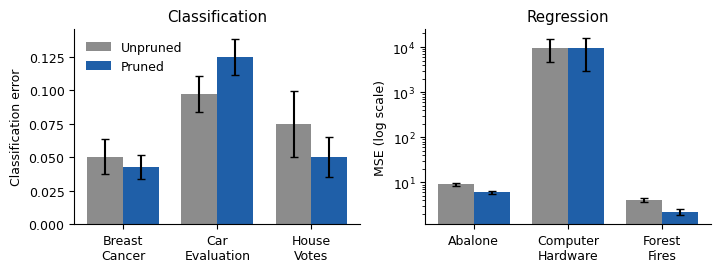

In [6]:
# Figure 1: test error (classification error and MSE are on different scales)
fig, axs = plt.subplots(1, 2, figsize=(7.2, 2.8))
grouped_bars(axs[0], classification, "unpruned_err", "pruned_err", "Classification error", title="Classification")
grouped_bars(axs[1], regression, "unpruned_err", "pruned_err", "MSE (log scale)", log=True, title="Regression")
axs[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(fig_dir / "fig_error.pdf")
plt.show()

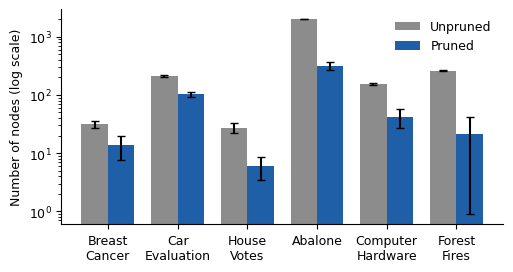

Saved: ['fig_error.pdf', 'fig_size.pdf']


In [7]:
# Figure 2: tree size (number of nodes)
fig, ax = plt.subplots(figsize=(5.2, 2.8))
grouped_bars(ax, order, "unpruned_size", "pruned_size", "Number of nodes (log scale)", log=True)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(fig_dir / "fig_size.pdf")
plt.show()

print("Saved:", sorted(p.name for p in fig_dir.glob("*.pdf")))